In [ ]:
import pandas as pd

df = pd.read_csv("/content/Survey_Responses_Brief.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print(df.info())

print(df.describe(include='all'))

Rows: 507
Columns: 20
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 507 entries, 0 to 506
Data columns (total 20 columns):
 #   Column                                                                            Non-Null Count  Dtype 
---  ------                                                                            --------------  ----- 
 0   Timestamp                                                                         507 non-null    object
 1   What is your age?                                                                 507 non-null    object
 2   What is your gender?                                                              507 non-null    object
 3   What is your highest education level?                                             507 non-null    object
 4   What is your current occupation?                                                  507 non-null    object
 5   What is your marital status?                                                      507 non-null    

In [ ]:
missing = df.isnull().sum()

print(missing)

print((missing/len(df))*100)

Timestamp                                                                           0
What is your age?                                                                   0
What is your gender?                                                                0
What is your highest education level?                                               0
What is your current occupation?                                                    0
What is your marital status?                                                        0
How satisfied are you with your life overall?                                       0
How would you rate your sleep quality?                                              0
How many hours do you spend on screens daily?                                       0
How often do you exercise or engage in physical activity?                           0
How often do you spend quality time with friends or family?                         0
How stressed do you feel due to academic or work press

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [ ]:
for col in df.columns:
    print("\n", col)
    print(df[col].value_counts())


 Timestamp
Timestamp
24/05/2026 10:56:07    2
24/05/2026 08:24:07    2
24/05/2026 00:10:07    2
28/05/2026 13:18:07    2
22/05/2026 17:23:07    2
                      ..
27/05/2026 03:49:07    1
25/05/2026 04:53:07    1
28/05/2026 12:31:07    1
27/05/2026 06:26:07    1
22/05/2026 12:22:07    1
Name: count, Length: 499, dtype: int64

 What is your age?
What is your age?
20          84
21          56
23          50
22          45
19          44
26          29
24          26
28          21
31          16
30          15
25          14
27          13
32          12
35          11
29          11
33          11
37           9
34           9
50           7
42           6
36           5
45           5
40           4
38           2
31 years     1
..           1
Name: count, dtype: int64

 What is your gender?
What is your gender?
Female    262
Male      245
Name: count, dtype: int64

 What is your highest education level?
What is your highest education level?
Undergraduate       295
Higher Sec

In [ ]:
depression_cols = [
"I couldn't seem to experience any positive feeling at all.",
'I found it difficult to work up the initiative to do things.',
'I felt that I had nothing to look forward to.',
'I felt sad and depressed.',
"I felt that I wasn't worth much as a person.",
'I felt that life was meaningless.',
'I felt I had lost interest in everything.'
]

df['Depression_Score'] = df[depression_cols].sum(axis=1)

In [ ]:
df['Depression_Label'] = (
    df['Depression_Score'] >= 10
).astype(int)

In [ ]:
print(
df['Depression_Label'].value_counts()
)

Depression_Label
0    392
1    115
Name: count, dtype: int64


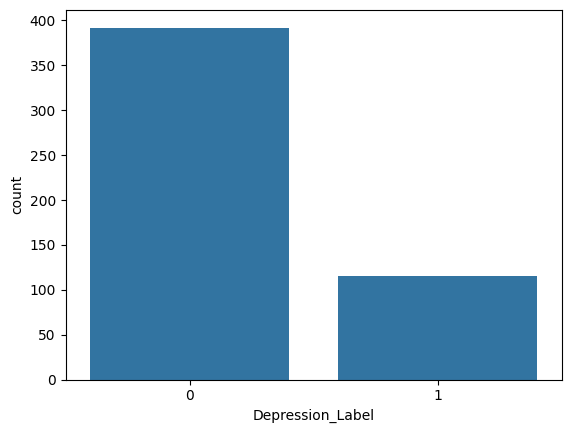

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
x='Depression_Label',
data=df
)

plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(
            df_encoded[col].astype(str)
        )

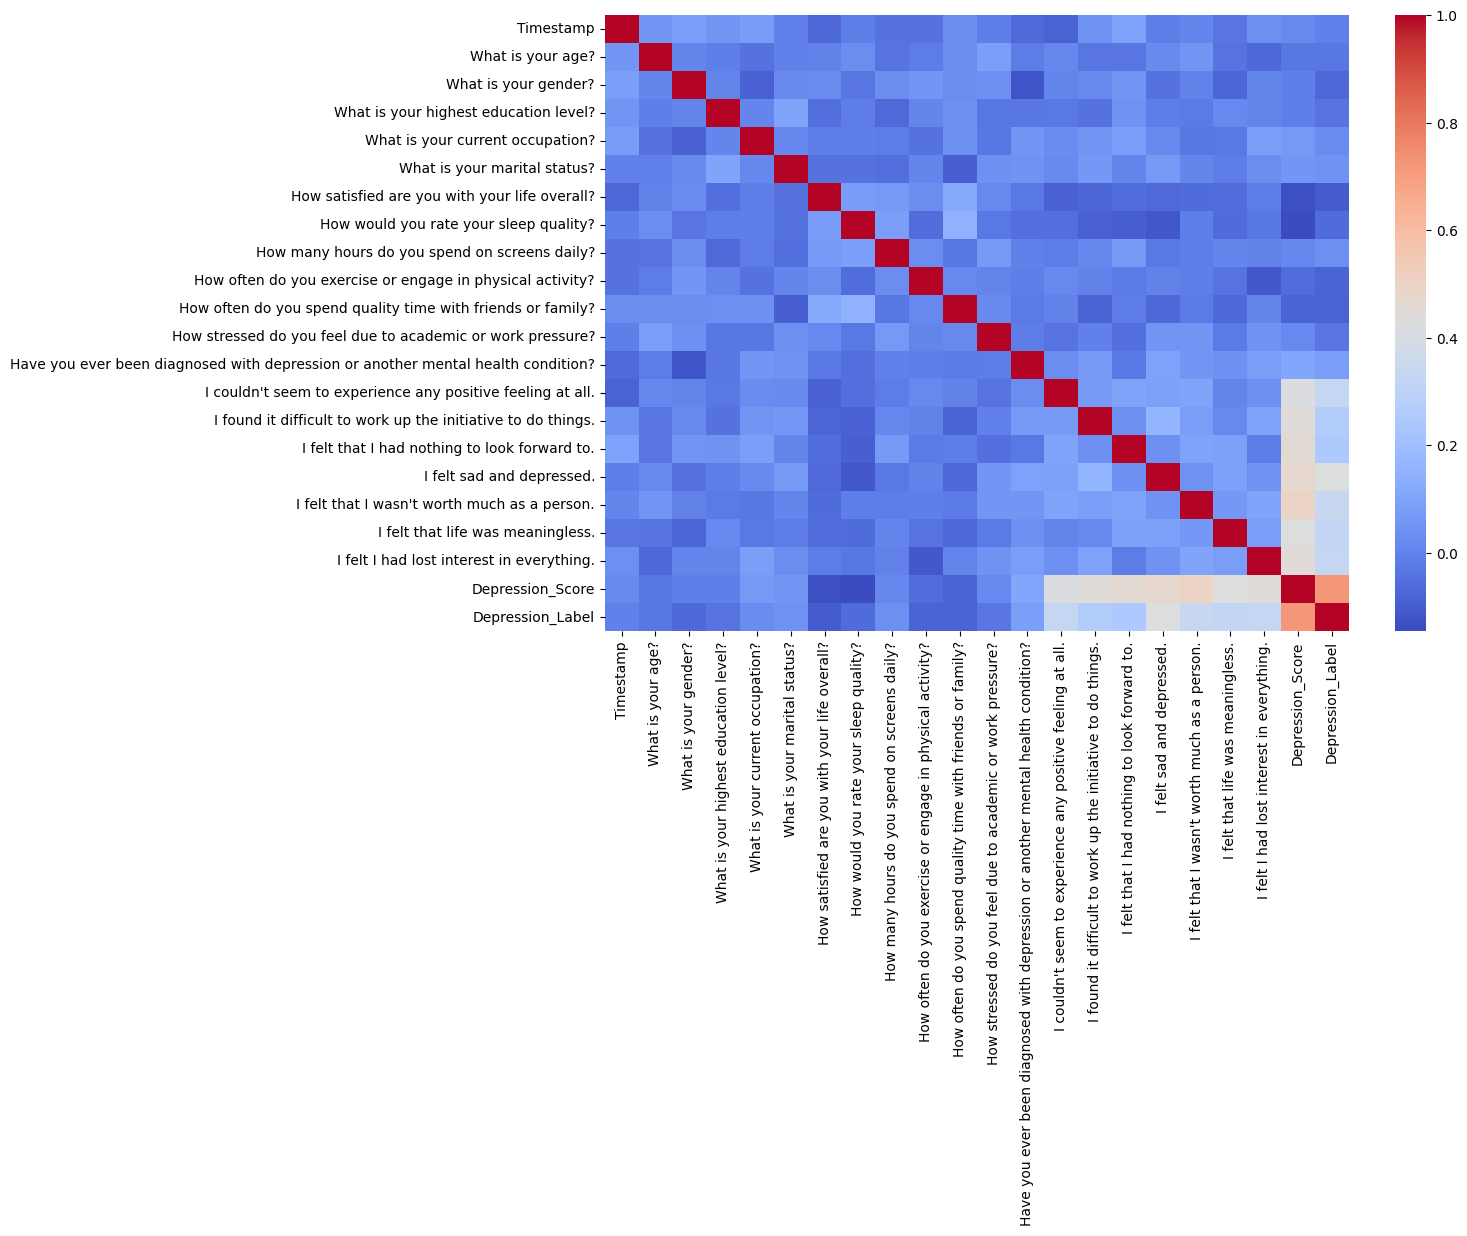

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(
df_encoded.corr(),
cmap='coolwarm'
)

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

X = df_encoded.drop(
['Depression_Label'],
axis=1
)

y = df_encoded['Depression_Label']

rf = RandomForestClassifier()

rf.fit(X,y)

importance = pd.DataFrame({
    'Feature':X.columns,
    'Importance':rf.feature_importances_
})

print(
importance.sort_values(
'Importance',
ascending=False
)
)

                                              Feature  Importance
20                                   Depression_Score    0.579285
16                          I felt sad and depressed.    0.077709
19          I felt I had lost interest in everything.    0.047404
18                  I felt that life was meaningless.    0.046555
17       I felt that I wasn't worth much as a person.    0.045541
13  I couldn't seem to experience any positive fee...    0.037722
15      I felt that I had nothing to look forward to.    0.030417
0                                           Timestamp    0.022175
14  I found it difficult to work up the initiative...    0.019263
1                                   What is your age?    0.017546
6       How satisfied are you with your life overall?    0.010710
10  How often do you spend quality time with frien...    0.009257
11  How stressed do you feel due to academic or wo...    0.009238
7              How would you rate your sleep quality?    0.008315
3         

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

In [ ]:
for col in df.columns:
    print(col)

Timestamp
What is your age?
What is your gender?
What is your highest education level?
What is your current occupation?
What is your marital status?
How satisfied are you with your life overall?
How would you rate your sleep quality?
How many hours do you spend on screens daily?
How often do you exercise or engage in physical activity?
How often do you spend quality time with friends or family?
How stressed do you feel due to academic or work pressure?
Have you ever been diagnosed with depression or another mental health condition?
I couldn't seem to experience any positive feeling at all.
I found it difficult to work up the initiative to do things.
I felt that I had nothing to look forward to.
I felt sad and depressed.
I felt that I wasn't worth much as a person.
I felt that life was meaningless.
I felt I had lost interest in everything.
Depression_Score
Depression_Label


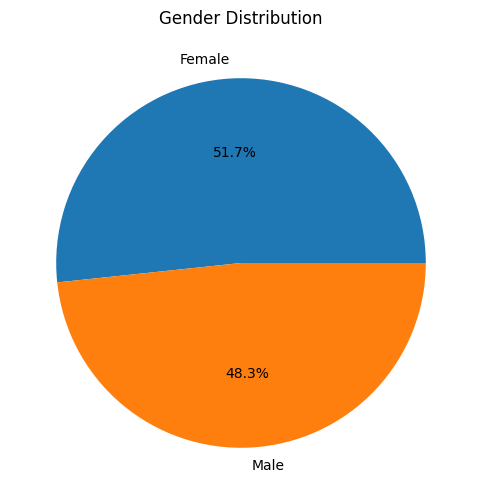

In [ ]:
plt.figure(figsize=(6,6))

df['What is your gender?'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.ylabel('')

plt.title('Gender Distribution')

plt.show()

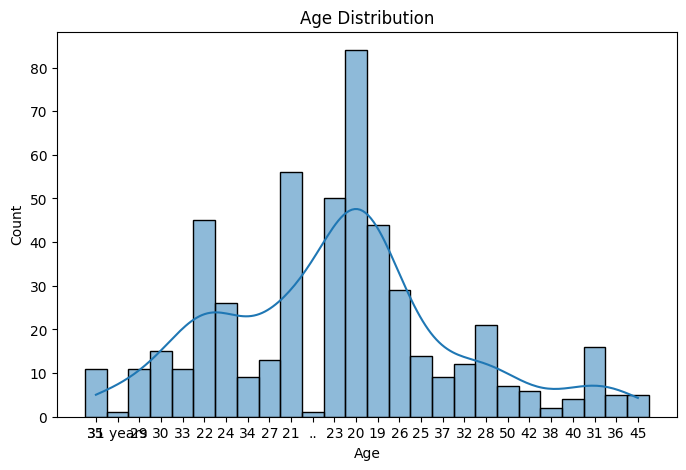

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['What is your age?'],
    bins=10,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

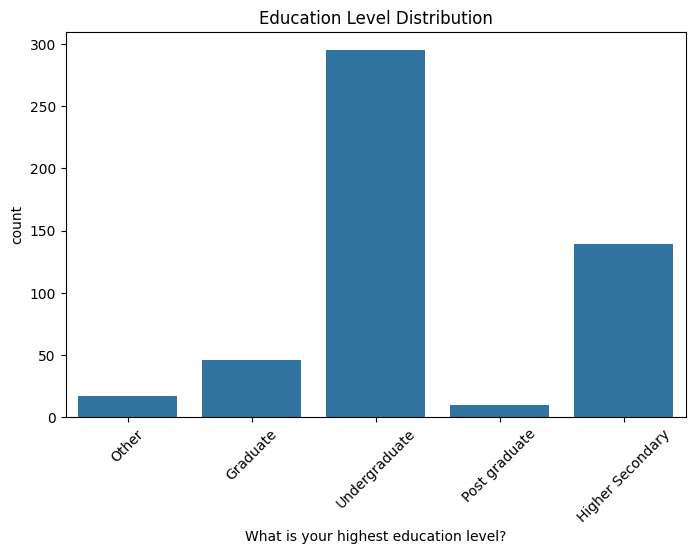

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='What is your highest education level?',
    data=df
)

plt.xticks(rotation=45)

plt.title("Education Level Distribution")

plt.show()

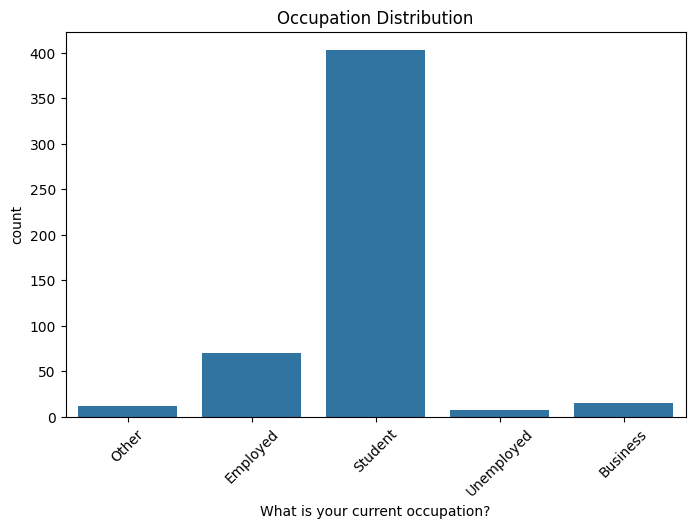

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='What is your current occupation?',
    data=df
)

plt.xticks(rotation=45)

plt.title("Occupation Distribution")

plt.show()

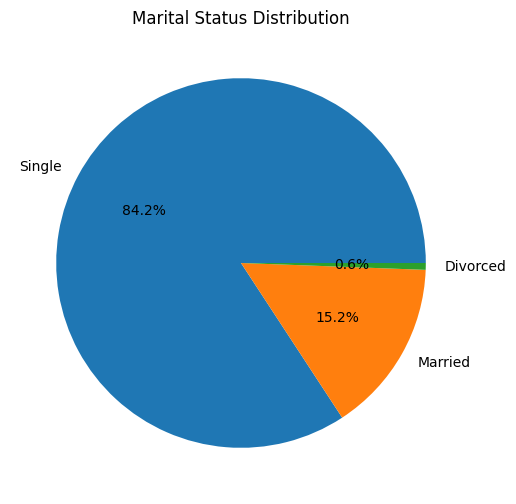

In [ ]:
plt.figure(figsize=(6,6))

df['What is your marital status?'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.ylabel("")

plt.title("Marital Status Distribution")

plt.show()

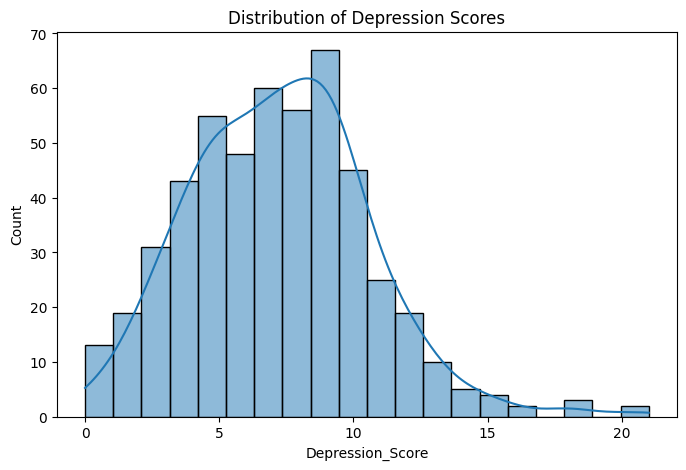

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['Depression_Score'],
    bins=20,
    kde=True
)

plt.title("Distribution of Depression Scores")

plt.show()

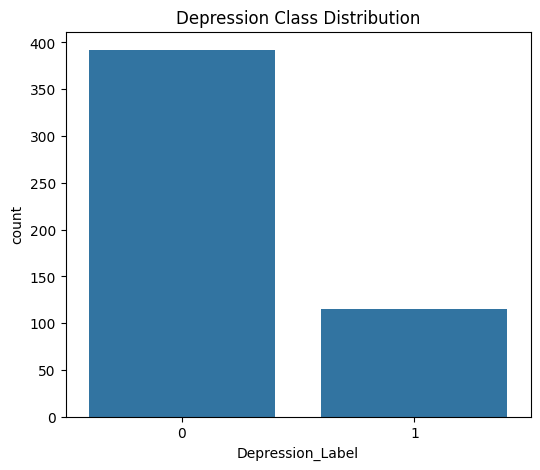

In [ ]:
plt.figure(figsize=(6,5))

sns.countplot(
    x='Depression_Label',
    data=df
)

plt.title("Depression Class Distribution")

plt.show()

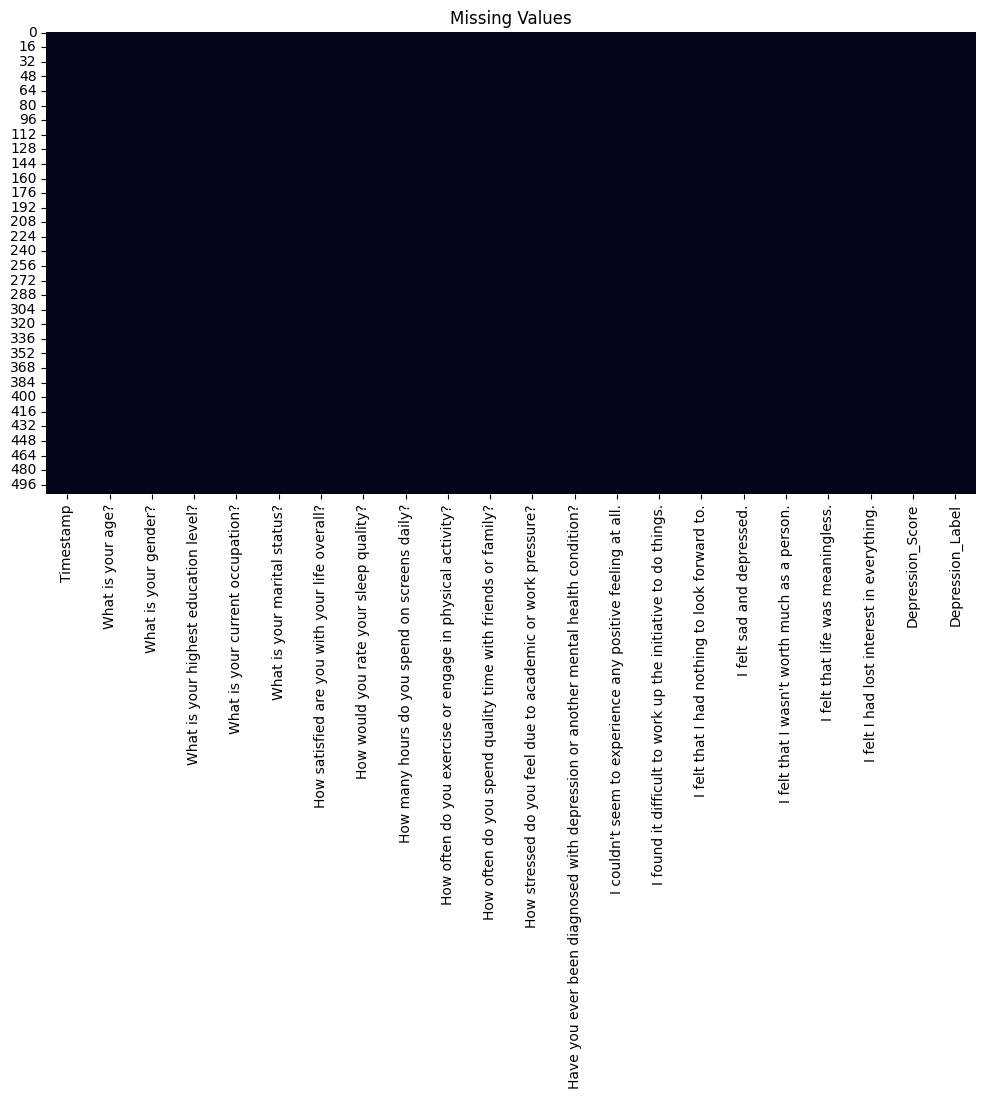

In [ ]:
plt.figure(figsize=(12,6))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.title("Missing Values")

plt.show()

In [ ]:
print(X.columns.tolist())

['Timestamp', 'What is your age?', 'What is your gender?', 'What is your highest education level?', 'What is your current occupation?', 'What is your marital status?', 'How satisfied are you with your life overall?', 'How would you rate your sleep quality?', 'How many hours do you spend on screens daily?', 'How often do you exercise or engage in physical activity?', 'How often do you spend quality time with friends or family?', 'How stressed do you feel due to academic or work pressure?', 'Have you ever been diagnosed with depression or another mental health condition?', "I couldn't seem to experience any positive feeling at all.", 'I found it difficult to work up the initiative to do things.', 'I felt that I had nothing to look forward to.', 'I felt sad and depressed.', "I felt that I wasn't worth much as a person.", 'I felt that life was meaningless.', 'I felt I had lost interest in everything.', 'Depression_Score']


In [ ]:
print(X.columns.tolist())

['Timestamp', 'What is your age?', 'What is your gender?', 'What is your highest education level?', 'What is your current occupation?', 'What is your marital status?', 'How satisfied are you with your life overall?', 'How would you rate your sleep quality?', 'How many hours do you spend on screens daily?', 'How often do you exercise or engage in physical activity?', 'How often do you spend quality time with friends or family?', 'How stressed do you feel due to academic or work pressure?', 'Have you ever been diagnosed with depression or another mental health condition?', "I couldn't seem to experience any positive feeling at all.", 'I found it difficult to work up the initiative to do things.', 'I felt that I had nothing to look forward to.', 'I felt sad and depressed.', "I felt that I wasn't worth much as a person.", 'I felt that life was meaningless.', 'I felt I had lost interest in everything.', 'Depression_Score']


In [ ]:
print('Depression_Score' in X.columns)
print('Depression_Label' in X.columns)
print('Timestamp' in X.columns)

True
False
True


In [ ]:
X = df_encoded.drop(
    [
        'Timestamp',
        'Depression_Score',
        'Depression_Label'
    ],
    axis=1,
    errors='ignore'
)

y = df_encoded['Depression_Label']

In [ ]:
print('Depression_Score' in X.columns)
print('Depression_Label' in X.columns)
print('Timestamp' in X.columns)

False
False
False


In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

for col in df_encoded.columns:

    if df_encoded[col].dtype == 'object':

        le = LabelEncoder()

        df_encoded[col] = le.fit_transform(
            df_encoded[col].astype(str)
        )

In [ ]:
print(len(X.columns))

19


In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

In [ ]:
X = df_encoded.drop(
    [
        'Timestamp',
        'Depression_Score',
        'Depression_Label'
    ],
    axis=1,
    errors='ignore'
)

y = df_encoded['Depression_Label']

print(X.shape)
print(y.shape)

(507, 19)
(507,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(405, 19)
(102, 19)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state=42
)

rf.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


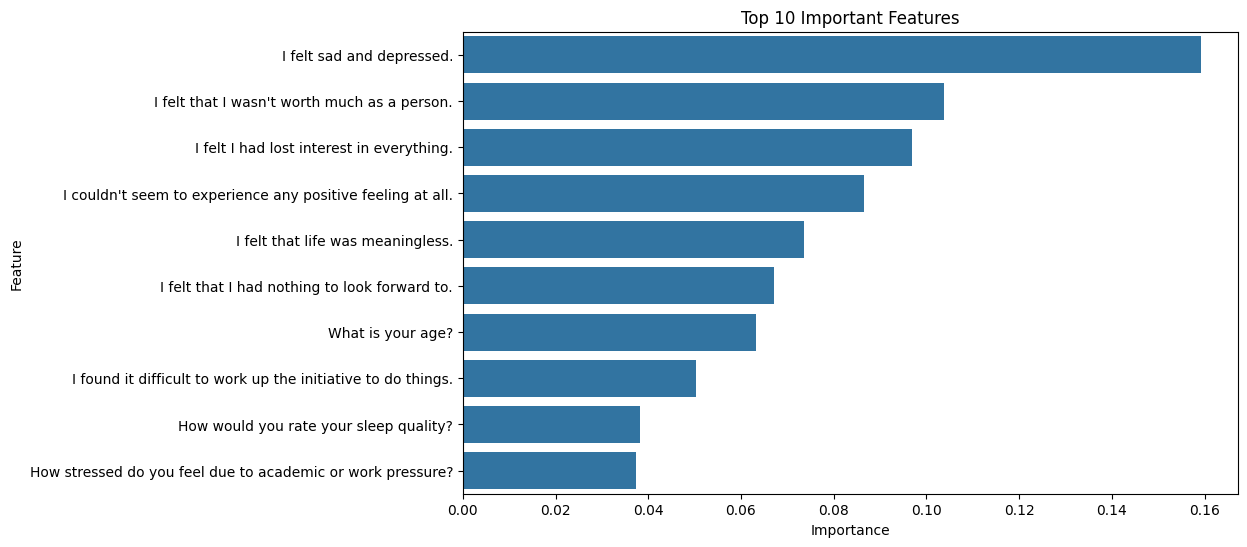

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.show()

In [ ]:
pd.crosstab(
    df['How would you rate your sleep quality?'],
    df['Depression_Label']
)

Depression_Label,0,1
How would you rate your sleep quality?,,
1,11,9
2,40,12
3,103,28
4,130,37
5,108,29


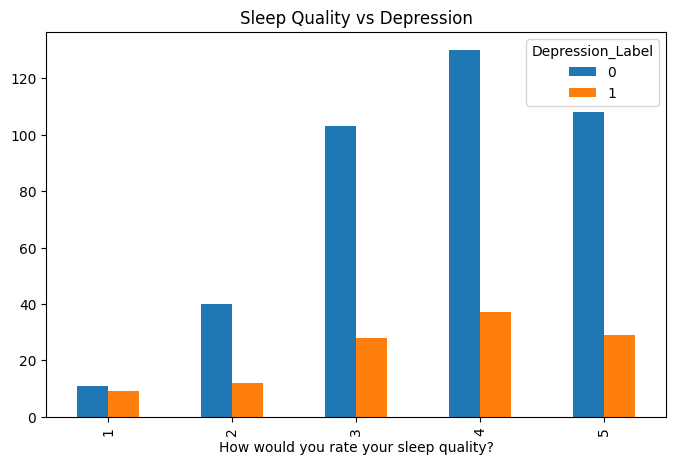

In [ ]:
pd.crosstab(
    df['How would you rate your sleep quality?'],
    df['Depression_Label']
).plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Sleep Quality vs Depression")
plt.show()

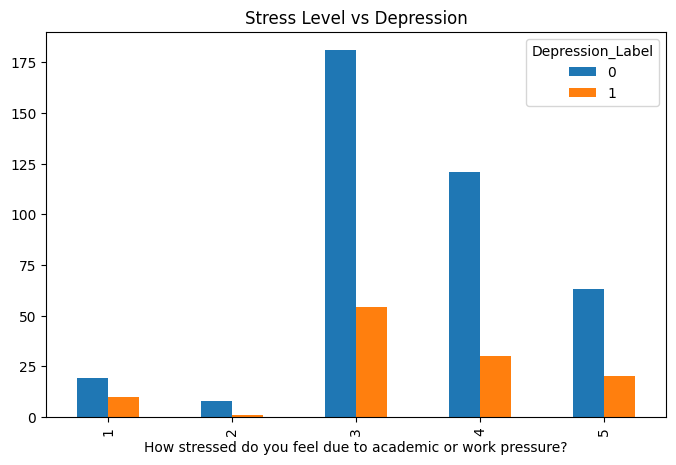

In [ ]:
pd.crosstab(
    df['How stressed do you feel due to academic or work pressure?'],
    df['Depression_Label']
).plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Stress Level vs Depression")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    matthews_corrcoef,
    cohen_kappa_score
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    matthews_corrcoef,
    cohen_kappa_score
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

def evaluate_model(model, X_test, y_test):

    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    mcc = matthews_corrcoef(y_test, pred)
    kappa = cohen_kappa_score(y_test, pred)

    print("Accuracy :", acc)
    print("Precision:", prec)
    print("Recall   :", rec)
    print("F1 Score :", f1)
    print("MCC      :", mcc)
    print("Kappa    :", kappa)

    return [acc, prec, rec, f1, mcc, kappa]

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train,y_train)

lr_results = evaluate_model(
    lr,
    X_test,
    y_test
)

Accuracy : 0.9803921568627451
Precision: 0.92
Recall   : 1.0
F1 Score : 0.9583333333333334
MCC      : 0.9469471266968889
Kappa    : 0.9455419113721303


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train,y_train)

dt_results = evaluate_model(
    dt,
    X_test,
    y_test
)

Accuracy : 0.8529411764705882
Precision: 0.6666666666666666
Recall   : 0.6956521739130435
F1 Score : 0.6808510638297872
MCC      : 0.5855896195920661
Kappa    : 0.5853658536585367


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train,y_train)

rf_results = evaluate_model(
    rf,
    X_test,
    y_test
)

Accuracy : 0.8921568627450981
Precision: 1.0
Recall   : 0.5217391304347826
F1 Score : 0.6857142857142857
MCC      : 0.6767355572841977
Kappa    : 0.6282306163021869


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train,y_train)

knn_results = evaluate_model(
    knn,
    X_test,
    y_test
)

Accuracy : 0.8235294117647058
Precision: 0.7777777777777778
Recall   : 0.30434782608695654
F1 Score : 0.4375
MCC      : 0.4111192067227398
Kappa    : 0.35578947368421043


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm = Pipeline([
    ('scaler',StandardScaler()),
    ('svc',SVC(probability=True))
])

svm.fit(X_train,y_train)

svm_results = evaluate_model(
    svm,
    X_test,
    y_test
)

Accuracy : 0.9509803921568627
Precision: 0.9090909090909091
Recall   : 0.8695652173913043
F1 Score : 0.8888888888888888
MCC      : 0.8578109032325878
Kappa    : 0.8574622694242593


In [ ]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train,y_train)

nb_results = evaluate_model(
    nb,
    X_test,
    y_test
)

Accuracy : 0.9313725490196079
Precision: 0.8333333333333334
Recall   : 0.8695652173913043
F1 Score : 0.851063829787234
MCC      : 0.8068123647712911
Kappa    : 0.8065040650406504


In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    random_state=42
)

ada.fit(X_train,y_train)

ada_results = evaluate_model(
    ada,
    X_test,
    y_test
)

Accuracy : 0.9607843137254902
Precision: 0.88
Recall   : 0.9565217391304348
F1 Score : 0.9166666666666666
MCC      : 0.8924081052835163
Kappa    : 0.8910838227442606


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    random_state=42
)

gb.fit(X_train,y_train)

gb_results = evaluate_model(
    gb,
    X_test,
    y_test
)

Accuracy : 0.9019607843137255
Precision: 0.8095238095238095
Recall   : 0.7391304347826086
F1 Score : 0.7727272727272727
MCC      : 0.7115864820491767
Kappa    : 0.7103918228279387


In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train,y_train)

xgb_results = evaluate_model(
    xgb,
    X_test,
    y_test
)

Accuracy : 0.8823529411764706
Precision: 0.72
Recall   : 0.782608695652174
F1 Score : 0.75
MCC      : 0.6742520196300265
Kappa    : 0.6732514682327817


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    rf,
    X,
    y,
    cv=5,
    scoring='f1'
)

print(scores)
print(scores.mean())

[0.78947368 0.68571429 0.57142857 0.35714286 0.5625    ]
0.5932518796992482


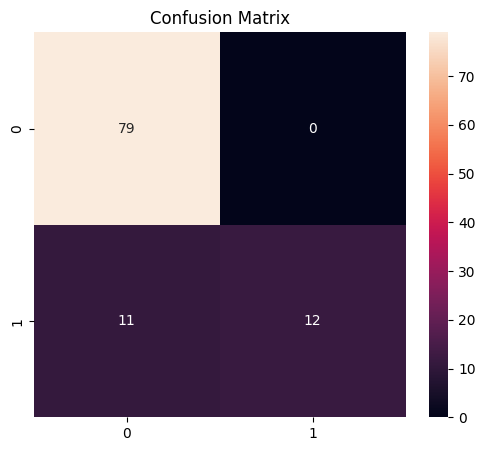

In [ ]:
pred = rf.predict(X_test)

cm = confusion_matrix(
    y_test,
    pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("Confusion Matrix")

plt.show()

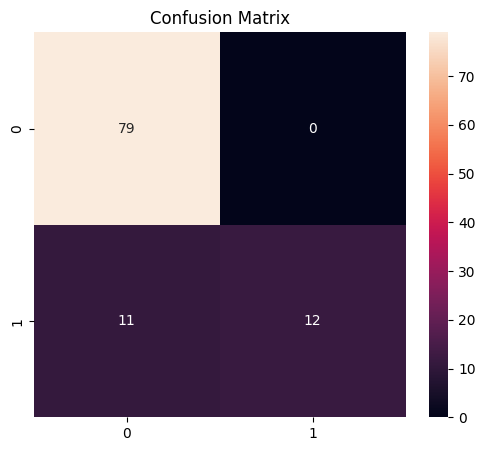

In [ ]:
pred = rf.predict(X_test)

cm = confusion_matrix(
    y_test,
    pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("Confusion Matrix")

plt.show()

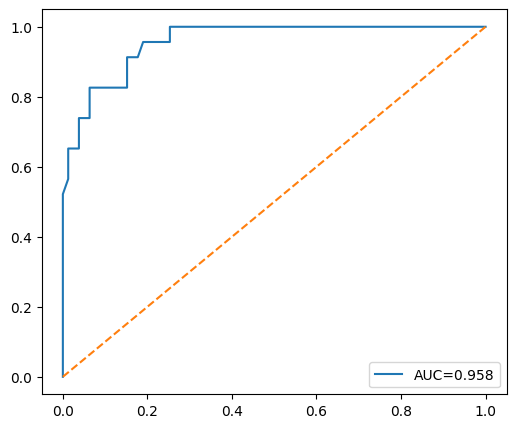

In [ ]:
from sklearn.metrics import roc_curve

prob = rf.predict_proba(
    X_test
)[:,1]

auc = roc_auc_score(
    y_test,
    prob
)

fpr,tpr,_ = roc_curve(
    y_test,
    prob
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC={auc:.3f}"
)

plt.plot([0,1],[0,1],'--')

plt.legend()

plt.show()

In [ ]:
importance = pd.DataFrame({
    'Feature':X.columns,
    'Importance':rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(10)

,Feature,Importance
15,I felt sad and depressed.,0.157845
16,I felt that I wasn't worth much as a person.,0.101071
18,I felt I had lost interest in everything.,0.099417
12,I couldn't seem to experience any positive fee...,0.087715
17,I felt that life was meaningless.,0.074456
14,I felt that I had nothing to look forward to.,0.065582
0,What is your age?,0.059561
13,I found it difficult to work up the initiative...,0.053351
6,How would you rate your sleep quality?,0.038043
10,How stressed do you feel due to academic or wo...,0.037729


In [ ]:
importance = pd.DataFrame({
    'Feature':X.columns,
    'Importance':rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(10)

,Feature,Importance
15,I felt sad and depressed.,0.157845
16,I felt that I wasn't worth much as a person.,0.101071
18,I felt I had lost interest in everything.,0.099417
12,I couldn't seem to experience any positive fee...,0.087715
17,I felt that life was meaningless.,0.074456
14,I felt that I had nothing to look forward to.,0.065582
0,What is your age?,0.059561
13,I found it difficult to work up the initiative...,0.053351
6,How would you rate your sleep quality?,0.038043
10,How stressed do you feel due to academic or wo...,0.037729


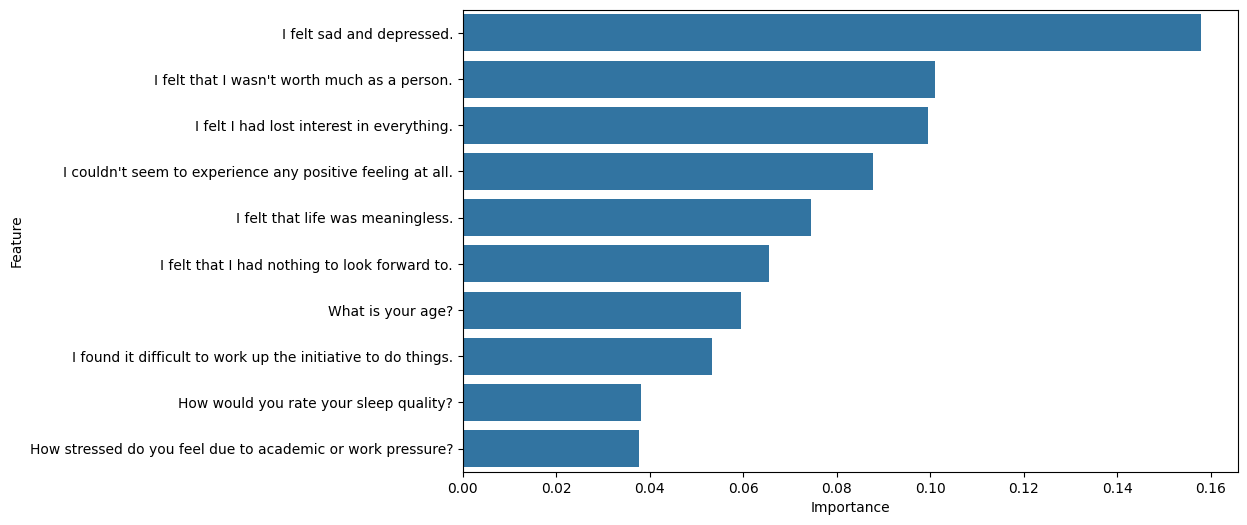

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.show()

In [ ]:
!pip install shap

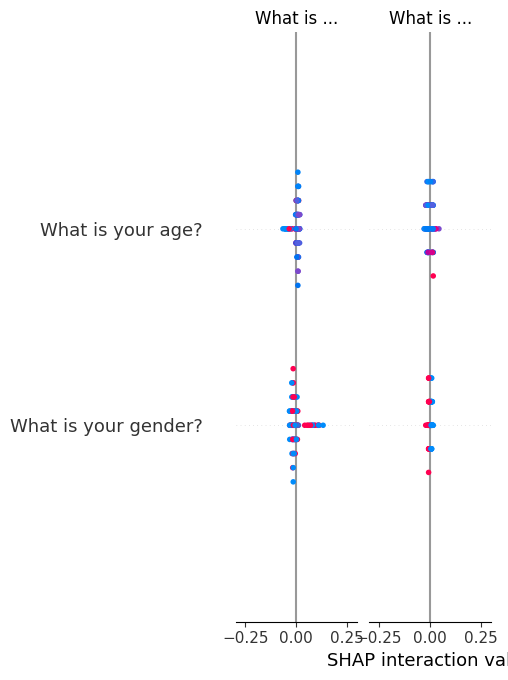

In [ ]:
import shap

explainer = shap.TreeExplainer(
    rf
)

shap_values = explainer.shap_values(
    X_test
)

shap.summary_plot(
    shap_values,
    X_test
)

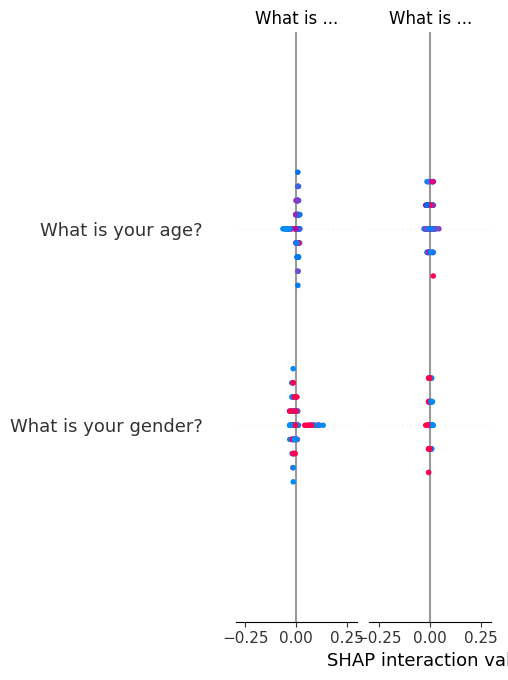

In [ ]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type='bar'
)

In [ ]:
print(type(shap_values))

<class 'numpy.ndarray'>


In [ ]:
print(shap_values.shape)
print(X_test.shape)

(102, 19, 2)
(102, 19)


In [ ]:
print(shap_values.shape)

(102, 19, 2)


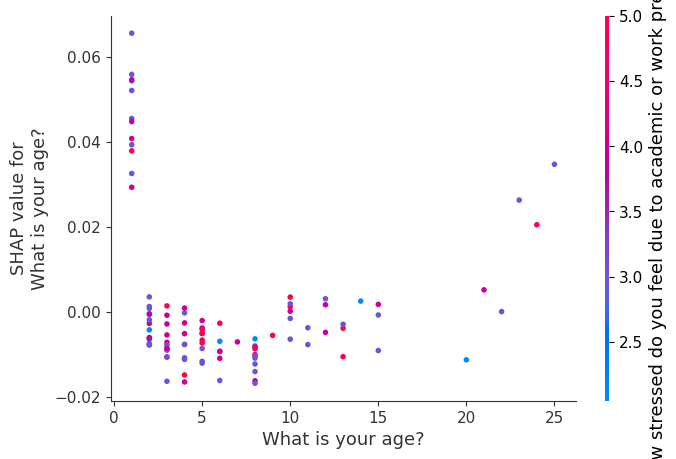

In [ ]:
shap.dependence_plot(
    X.columns[0],
    shap_values[:, :, 1],
    X_test
)

In [ ]:
print("Expected Value:", explainer.expected_value)

Expected Value: [0.77158025 0.22841975]


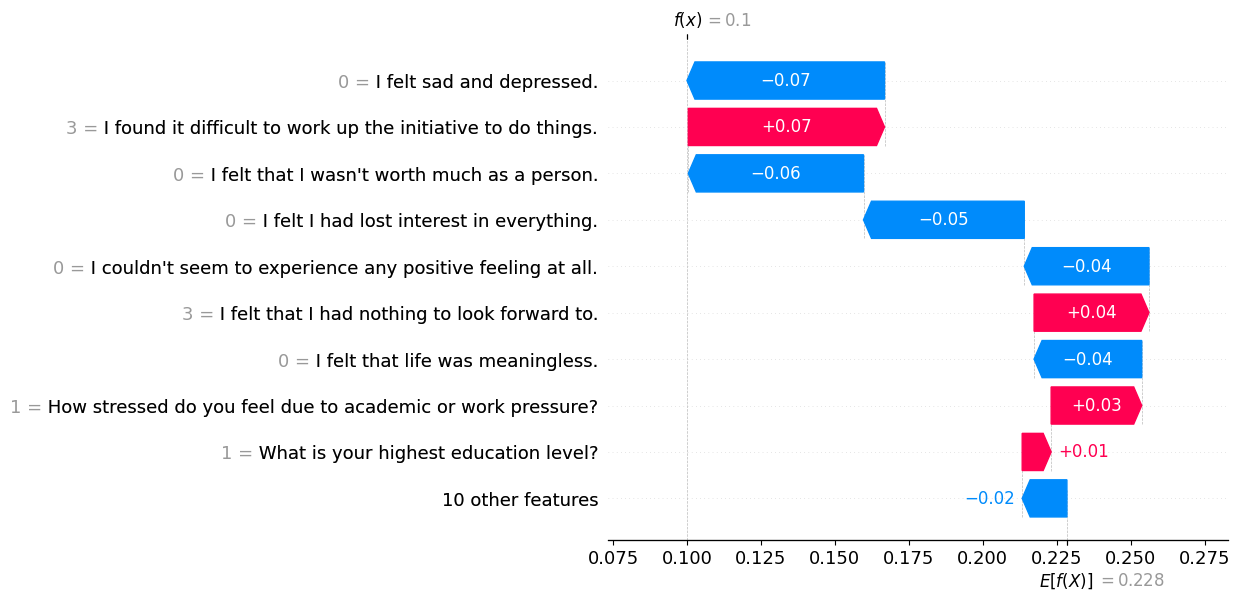

In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0,:,1],
        base_values=explainer.expected_value[1],
        data=X_test.iloc[0],
        feature_names=X_test.columns
    )
)

In [ ]:
!pip install lime

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


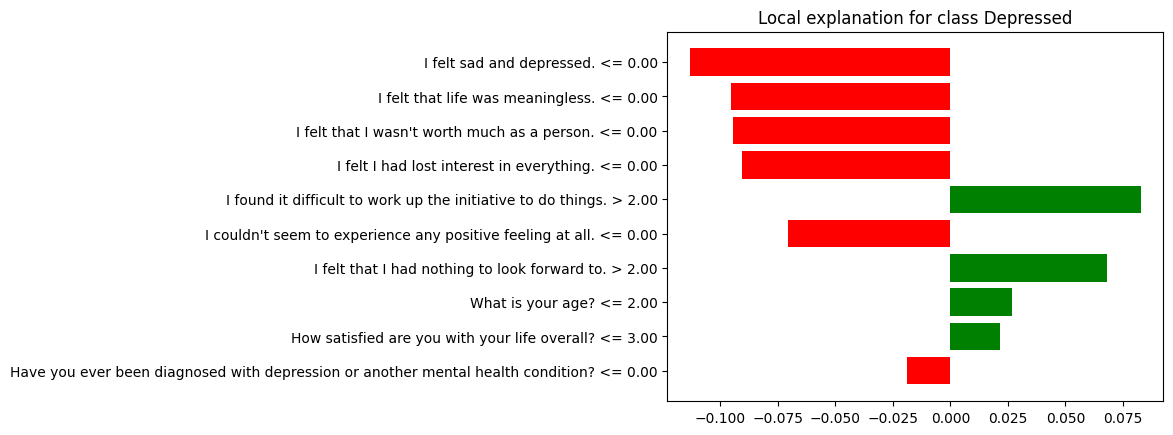

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    X_train.values,
    feature_names=X.columns,
    class_names=['Normal','Depressed'],
    mode='classification'
)

exp = lime_explainer.explain_instance(
    X_test.iloc[0].values,
    rf.predict_proba
)

exp.as_pyplot_figure()

plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


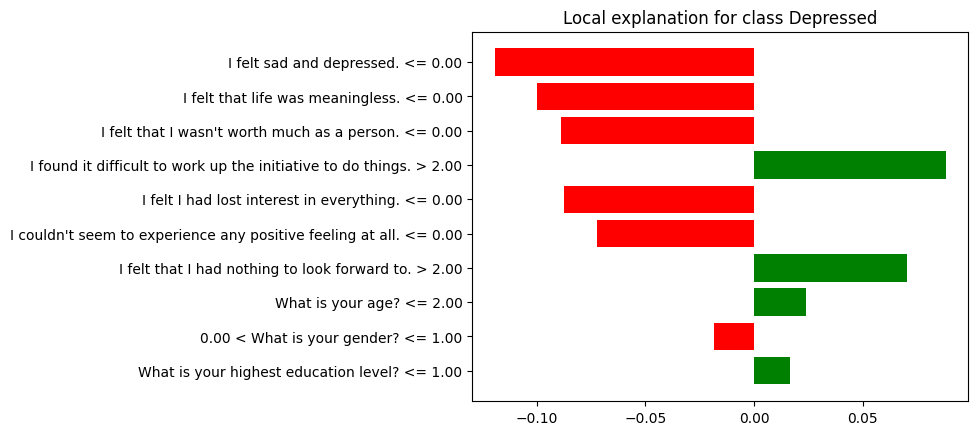

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X.columns.tolist(),
    class_names=['Normal','Depressed'],
    mode='classification'
)

exp = lime_explainer.explain_instance(
    X_test.iloc[0].values,
    rf.predict_proba,
    num_features=10
)

exp.as_pyplot_figure()

plt.show()

In [ ]:
results = pd.DataFrame({
    'Model':['LR','DT','RF','XGB'],
    'Accuracy':[
        lr_results[0],
        dt_results[0],
        rf_results[0],
        xgb_results[0]
    ],
    'Precision':[
        lr_results[1],
        dt_results[1],
        rf_results[1],
        xgb_results[1]
    ],
    'Recall':[
        lr_results[2],
        dt_results[2],
        rf_results[2],
        xgb_results[2]
    ],
    'F1-Score':[
        lr_results[3],
        dt_results[3],
        rf_results[3],
        xgb_results[3]
    ],
    'MCC':[
        lr_results[4],
        dt_results[4],
        rf_results[4],
        xgb_results[4]
    ],
    'Kappa':[
        lr_results[5],
        dt_results[5],
        rf_results[5],
        xgb_results[5]
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score,MCC,Kappa
0,LR,0.980392,0.920000,1.000000,0.958333,0.946947,0.945542
1,DT,0.852941,0.666667,0.695652,0.680851,0.585590,0.585366
2,RF,0.892157,1.000000,0.521739,0.685714,0.676736,0.628231
3,XGB,0.882353,0.720000,0.782609,0.750000,0.674252,0.673251


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    prec = precision_score(
        y_test,
        y_pred,
        average='weighted'
    )

    rec = recall_score(
        y_test,
        y_pred,
        average='weighted'
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    return acc, prec, rec, f1

In [ ]:
lr_acc, lr_prec, lr_rec, lr_f1 = evaluate_model(
    lr,
    X_test,
    y_test
)

print(lr_acc)

0.9803921568627451


In [ ]:
dt_acc, dt_prec, dt_rec, dt_f1 = evaluate_model(
    dt,
    X_test,
    y_test
)

In [ ]:
rf_acc, rf_prec, rf_rec, rf_f1 = evaluate_model(
    rf,
    X_test,
    y_test
)

In [ ]:
xgb_acc, xgb_prec, xgb_rec, xgb_f1 = evaluate_model(
    xgb,
    X_test,
    y_test
)

In [ ]:
knn_acc, knn_prec, knn_rec, knn_f1 = evaluate_model(
    knn,
    X_test,
    y_test
)

In [ ]:
svm_acc, svm_prec, svm_rec, svm_f1 = evaluate_model(
    svm,
    X_test,
    y_test
)

In [ ]:
nb_acc, nb_prec, nb_rec, nb_f1 = evaluate_model(
    nb,
    X_test,
    y_test
)

In [ ]:
ada_acc, ada_prec, ada_rec, ada_f1 = evaluate_model(
    ada,
    X_test,
    y_test
)

In [ ]:
gb_acc, gb_prec, gb_rec, gb_f1 = evaluate_model(
    gb,
    X_test,
    y_test
)

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=100,
    random_state=42
)

et.fit(X_train, y_train)

ExtraTreesClassifier(random_state=42)

In [ ]:
et_acc, et_prec, et_rec, et_f1 = evaluate_model(
    et,
    X_test,
    y_test
)

In [ ]:
results = pd.DataFrame({

    'Model':[
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost',
        'KNN',
        'SVM',
        'Naive Bayes',
        'AdaBoost',
        'Gradient Boosting',
        'Extra Trees'
    ],

    'Accuracy':[
        lr_acc,
        dt_acc,
        rf_acc,
        xgb_acc,
        knn_acc,
        svm_acc,
        nb_acc,
        ada_acc,
        gb_acc,
        et_acc
    ],

    'Precision':[
        lr_prec,
        dt_prec,
        rf_prec,
        xgb_prec,
        knn_prec,
        svm_prec,
        nb_prec,
        ada_prec,
        gb_prec,
        et_prec
    ],

    'Recall':[
        lr_rec,
        dt_rec,
        rf_rec,
        xgb_rec,
        knn_rec,
        svm_rec,
        nb_rec,
        ada_rec,
        gb_rec,
        et_rec
    ],

    'F1':[
        lr_f1,
        dt_f1,
        rf_f1,
        xgb_f1,
        knn_f1,
        svm_f1,
        nb_f1,
        ada_f1,
        gb_f1,
        et_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.980392,0.981961,0.980392,0.980675
1,Decision Tree,0.852941,0.855329,0.852941,0.854037
2,Random Forest,0.892157,0.905338,0.892157,0.878720
3,XGBoost,0.882353,0.886570,0.882353,0.884050
4,KNN,0.823529,0.816642,0.823529,0.792108
5,SVM,0.950980,0.950457,0.950980,0.950590
6,Naive Bayes,0.931373,0.932629,0.931373,0.931884
7,AdaBoost,0.960784,0.962883,0.960784,0.961350
8,Gradient Boosting,0.901961,0.899678,0.901961,0.900345
9,Extra Trees,0.892157,0.905338,0.892157,0.878720


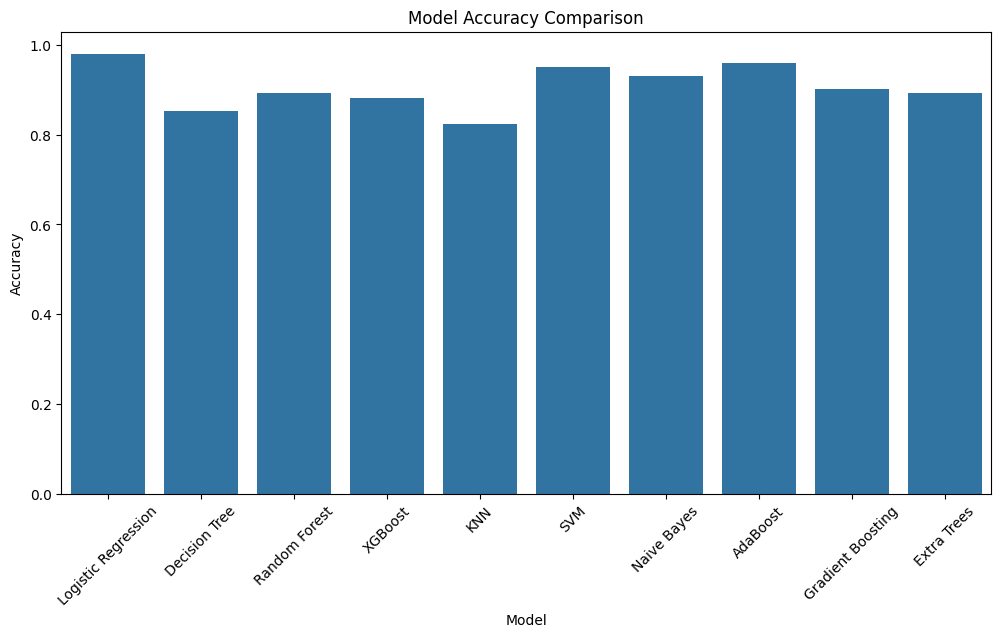

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.xticks(rotation=45)
plt.title("Model Accuracy Comparison")
plt.show()

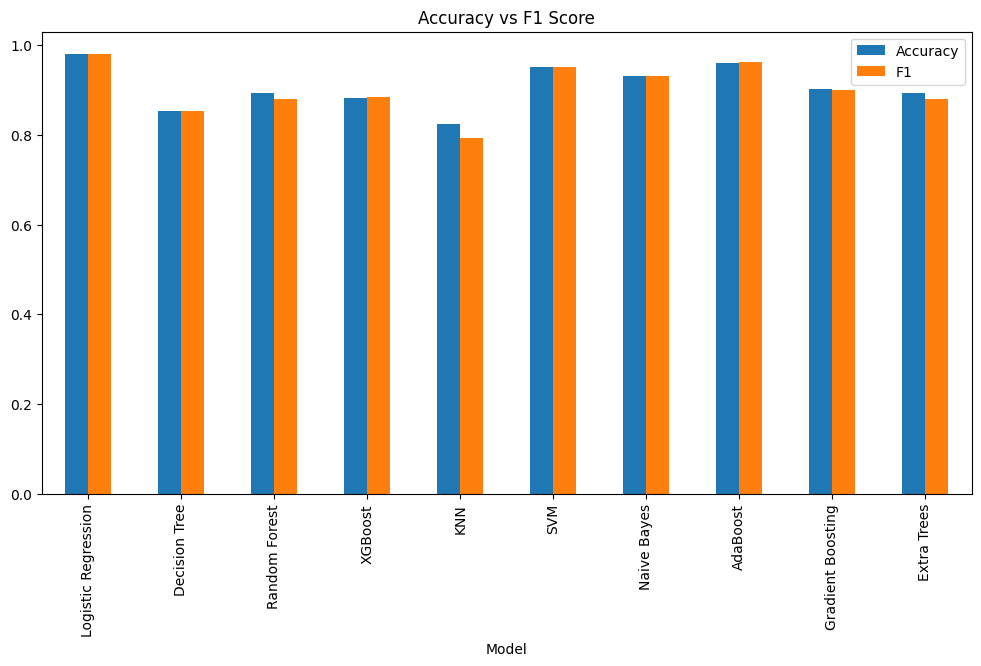

In [ ]:
results.plot(
    x='Model',
    y=['Accuracy','F1'],
    kind='bar',
    figsize=(12,6)
)

plt.title("Accuracy vs F1 Score")
plt.show()